# TP3 – Predicción Lineal

# Grupo N° 4

| Integrante | Legajo |
|---|---|
| *Pedro Stefoni Rey Iraola* | *64903* |
| *Vito Pensa Piccolo* | *63426* |
| *Javier Baltasar Pérez Losada* | *64589* |

**Fecha de entrega:** 15/10/2026

## 1. 

Los audios de los sonidos /a/ y /sh/ fueron grabados con Audacity. La frecuencia de muestreo que se usó es de 16 kHz, canal mono, duración 1 segundo, formato WAV (sin compresión) y codificación PCM 16-bit, que para un segundo a 16 kHz equivale a 256 kbps, como se puede ver en la figura.

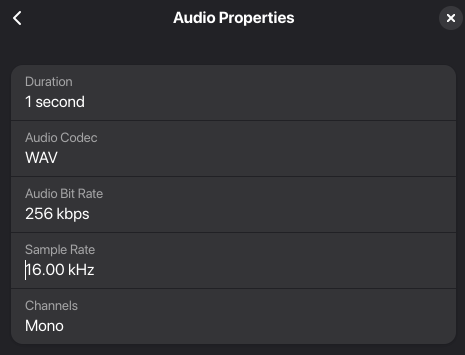

A simple vista, la señal que corresponde a /a/, tiene aspecto cuasi-periódico

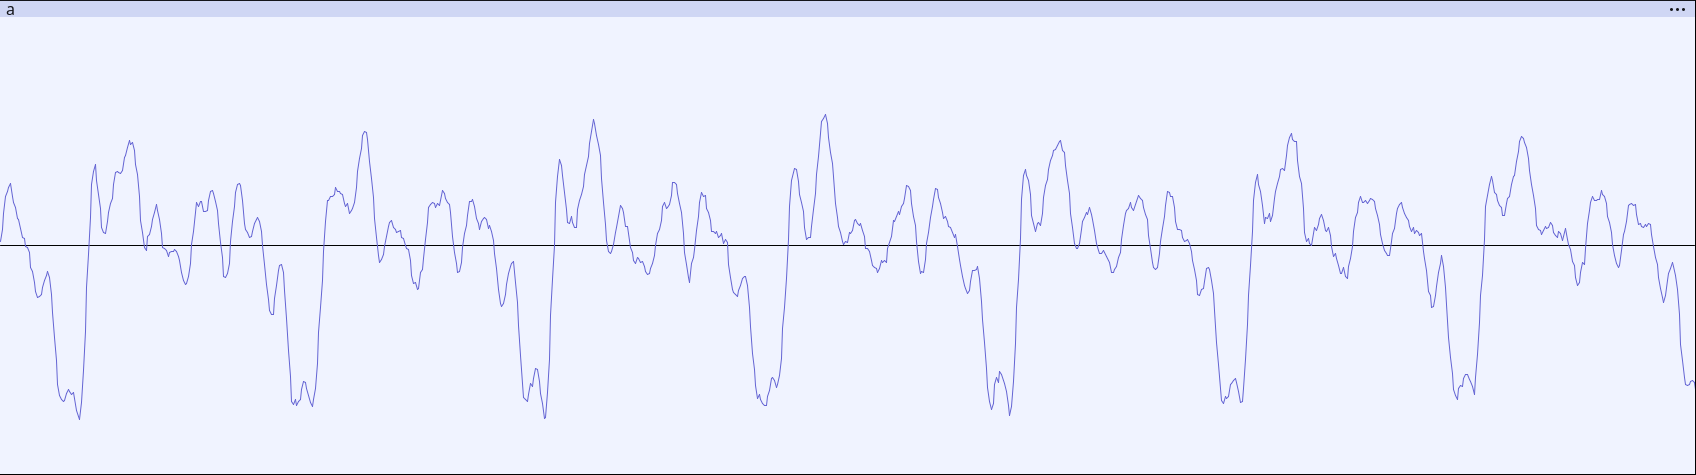

Con un periodo equivalente a $N_0=138$ muestras (este valor parece ser más exacto que la medición de segundos en Audacity), lo que equivale a 
$$ f_0 = \frac{f_s}{N_0} \approx 116\;\text{Hz.}$$

Por otro lado, la señal que corresponde a /sh/, tanto en su aspecto en el tiempo como psicoacústico, tiene toda la pinta de ruido blanco.

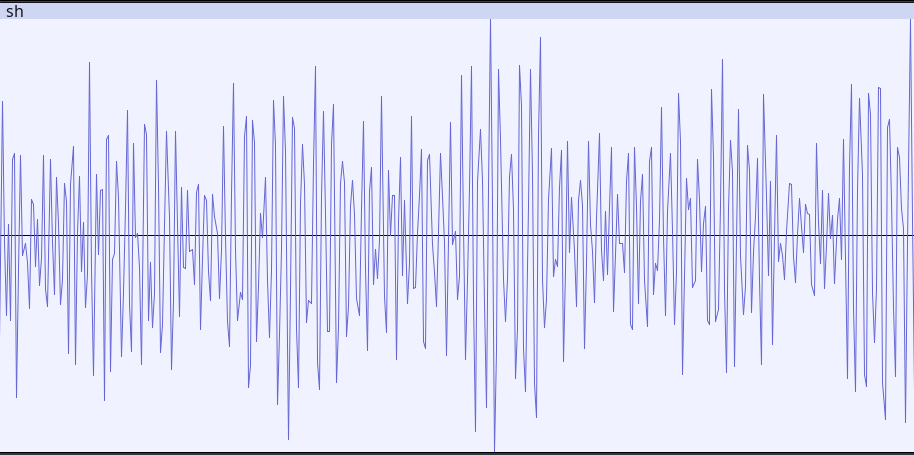

## 2.

Con la siguiente celda se calculan el FLP para /a/ y /sh/. Utilizamos el algoritmo de Levinson-Durbin, ya que es idóeo para estre problema, ya que es un problema de de predicción, i.e. un sistema de ecuaciones Toeplitz. Se grafica $J(M)$ y el error para distintos valores de $M$. 


/a/: 16010 muestras, 1.001 s, fs=16000 Hz
/sh/: 16022 muestras, 1.001 s, fs=16000 Hz


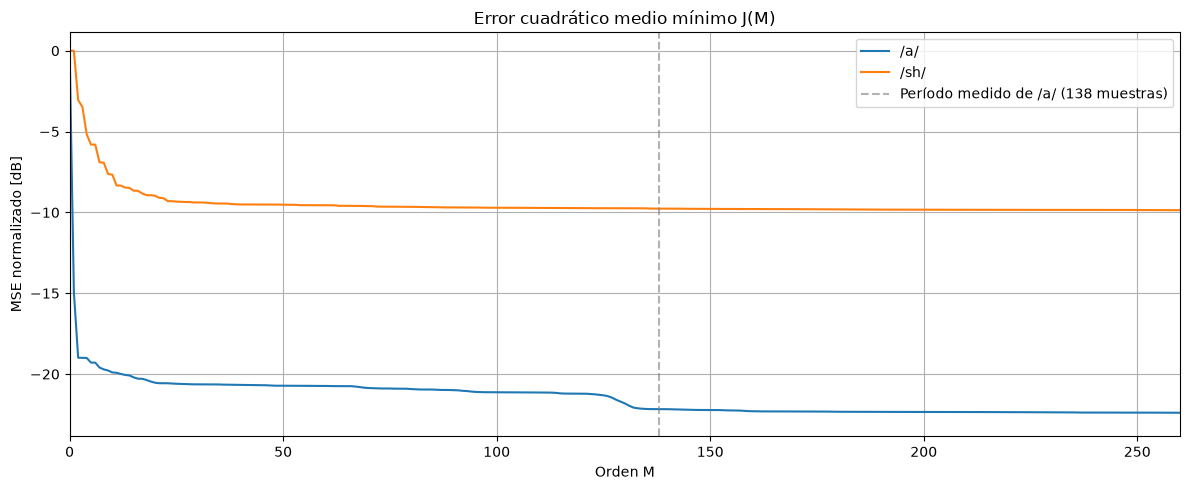

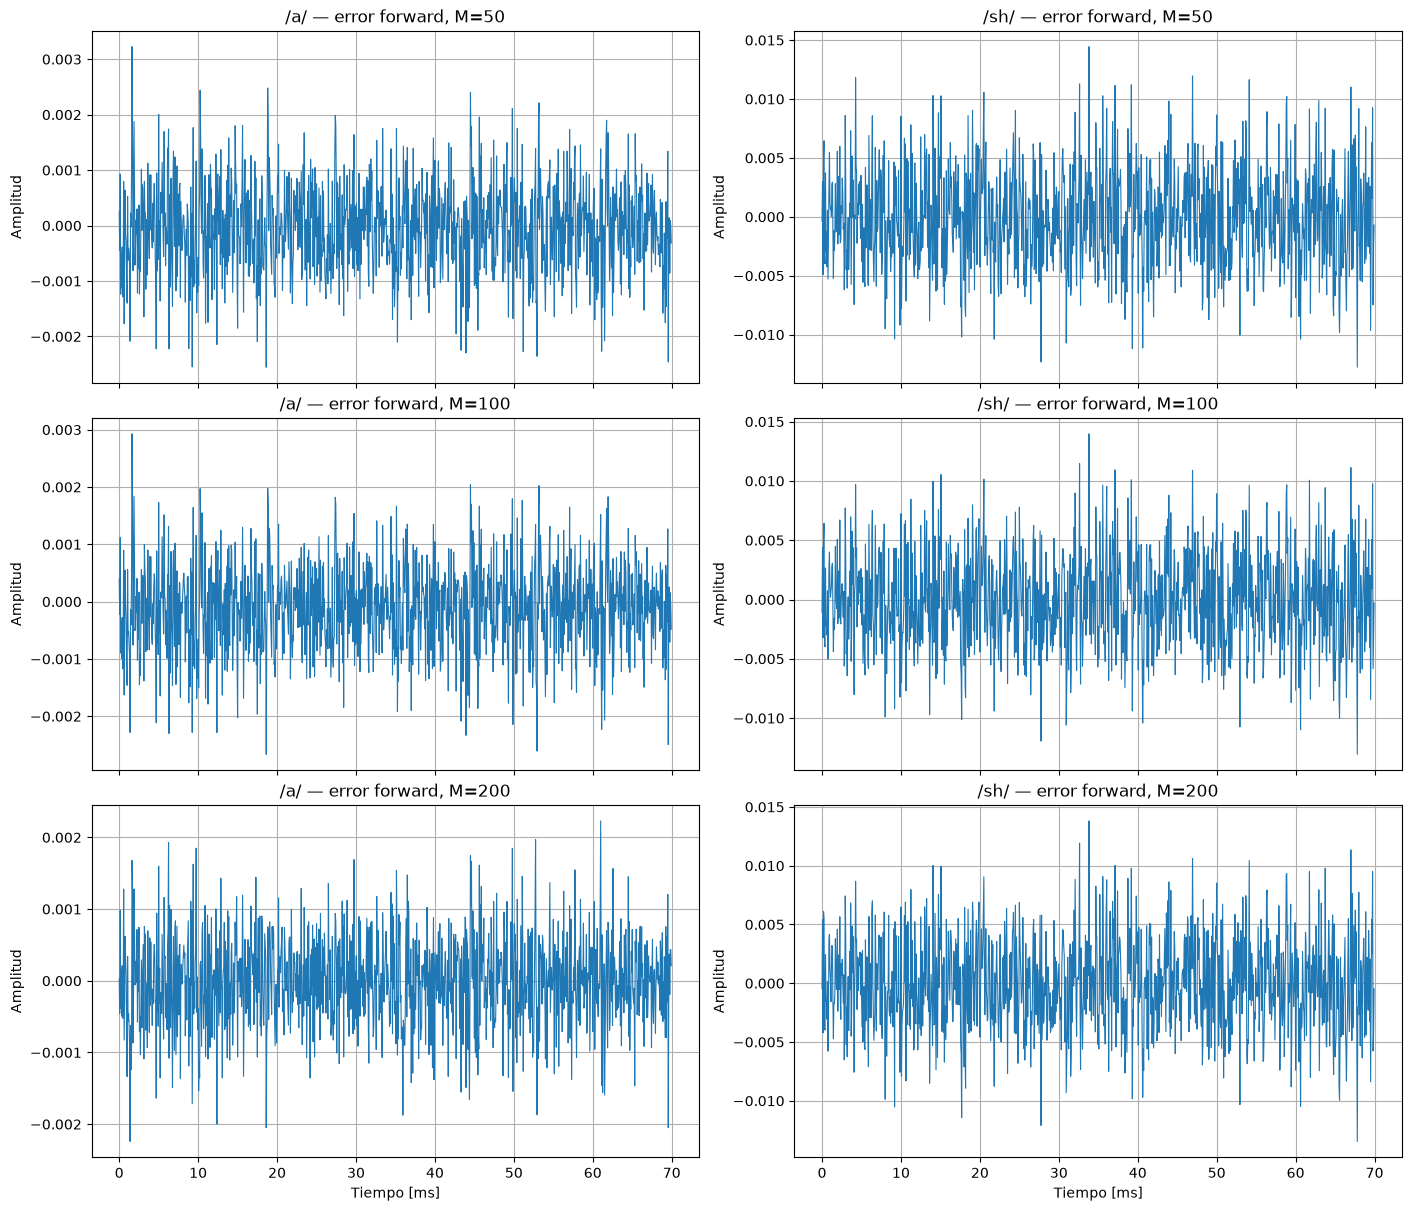

In [1]:

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import correlate, lfilter

# Parámetros
ARCHIVOS = {"a": "./audio/a.wav", "sh": "./audio/sh.wav"}
FS = 16000
M_MAX = 1000 # Valor razonable


def autocorrelacion(x, M):
    """Autocorrelación sesgada: r[l] = (1/N) * sum(x[n]*x[n-l])."""
    N = len(x)
    return correlate(x, x, mode="full", method="fft")[N-1:N+M] / N


def levinson_durbin(r, M):
    """
    Predicción forward óptima para órdenes 0,...,M.
    Devuelve:
        J[m]: MSE mínimo para orden m
        A[m]: coeficientes [1, a1, ..., am] del filtro de error
    """
    J = np.empty(M + 1)
    J[0] = r[0]
    A = [np.array([1.0])]

    for m in range(1, M + 1):
        a_prev = A[-1]

        # Correlación residual
        beta = r[m] + np.dot(a_prev[1:], r[m-1:0:-1])

        # Coeficiente de reflexión
        k = -beta / J[m-1]

        # Actualización de los coeficientes del predictor
        a = np.append(a_prev, 0.0)
        a[1:m] = a_prev[1:] + k * a_prev[1:][::-1]
        a[m] = k

        # Actualización del MSE mínimo
        J[m] = J[m-1] * (1 - k**2)

        A.append(a)

    return J, A


# Procesamiento de las grabaciones completas
resultados = {}

for sonido, archivo in ARCHIVOS.items():
    x, fs = sf.read(archivo)

    assert fs == FS, f"{archivo}: frecuencia de muestreo incorrecta ({fs} Hz)"
    assert x.ndim == 1, f"{archivo}: el audio debe ser mono"

    x = x - np.mean(x)  # Eliminar componente continua

    r = autocorrelacion(x, M_MAX)
    J, A = levinson_durbin(r, M_MAX)

    resultados[sonido] = {"x": x, "r": r, "J": J, "A": A}
    print(f"/{sonido}/: {len(x)} muestras, {len(x)/FS:.3f} s, fs={fs} Hz")


# ============================================================
# 1. MSE mínimo J(M) — ambas señales superpuestas
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

M_GRAFICO = 260  # Solo limita la visualización, no el cálculo

for sonido in ("a", "sh"):
    J = resultados[sonido]["J"]
    J_dB = 10 * np.log10(J / J[0])

    ax.plot(np.arange(len(J)), J_dB, label=f"/{sonido}/", linewidth=1.5)

ax.axvline(138, color="gray", linestyle="--", alpha=0.6,
           label="Período medido de /a/ (138 muestras)")

ax.set_xlim(0, min(M_GRAFICO, M_MAX))
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE normalizado [dB]")
ax.set_title("Error cuadrático medio mínimo J(M)")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. Error de predicción forward para distintos órdenes M
# ============================================================

ORDENES_ERROR = [50, 100, 200]

T_INICIO = 0.30
T_FIN = 0.37  # 70 ms, aproximadamente 8 períodos de /a/

i0 = int(T_INICIO * FS)
i1 = int(T_FIN * FS)

t = np.arange(i1 - i0) / FS * 1000  # Tiempo relativo en ms

fig, axes = plt.subplots(
    len(ORDENES_ERROR), 2,
    figsize=(14, 12),
    sharex=True,
    layout="constrained"
)

for col, sonido in enumerate(("a", "sh")):
    x = resultados[sonido]["x"]
    A = resultados[sonido]["A"]

    for fila, M in enumerate(ORDENES_ERROR):
        # Filtro del error de predicción: A(z)
        e = lfilter(A[M], [1.0], x)

        ax = axes[fila, col]
        ax.plot(t, e[i0:i1], linewidth=0.8)

        ax.set_title(f"/{sonido}/ — error forward, M={M}")
        ax.set_ylabel("Amplitud")
        ax.grid(True)

        if fila == len(ORDENES_ERROR) - 1:
            ax.set_xlabel("Tiempo [ms]")

plt.show()


Es notable que para el "segundo codo" de $J(M)$ de /a/ se da luego de $N_0$. Con la ayuda de un LLM (GPT-6), interpretamos esto a partir del modelo fuente-filtro de la voz: la vocal /a/ se genera por una excitación glotal cuasiperiódica (vibración de las cuerdas vocales) filtrada por las resonancias del tracto vocal. El primer codo se asocia principalmente al modelado de ese filtro vocal, mientras que el segundo aparece cuando el predictor alcanza retardos del orden de $N_0$ y comienza a explotar también la periodicidad de la excitación glotal. Recordemos que $N_0$ es el periodo de la señal en muestras, y justamente cuando el orden del filtro M es tal que llega a ver un periodo entero de la señal, va a predecir mejor. El problema con "sh es que no tiene un periodo fijo dado que se parece mucho al ruido blanco, por eso directamente no tiene segundo codo, como si se vé en el "a"-

Para poder analizar qué le sucede a la señal de error _forward_ de /a/ y qué componentes armónicas están más presentes en la señal, le aplicamos una FFT con ventana de Hann; ya que las mediciones temporales son muy ruidosas como para poder inferir algo. Sólo se gráfica $e^f(n)$ de /a/, dado que, como se dijo antes, la señal de /sh/ es prácticamente ruido blanco.

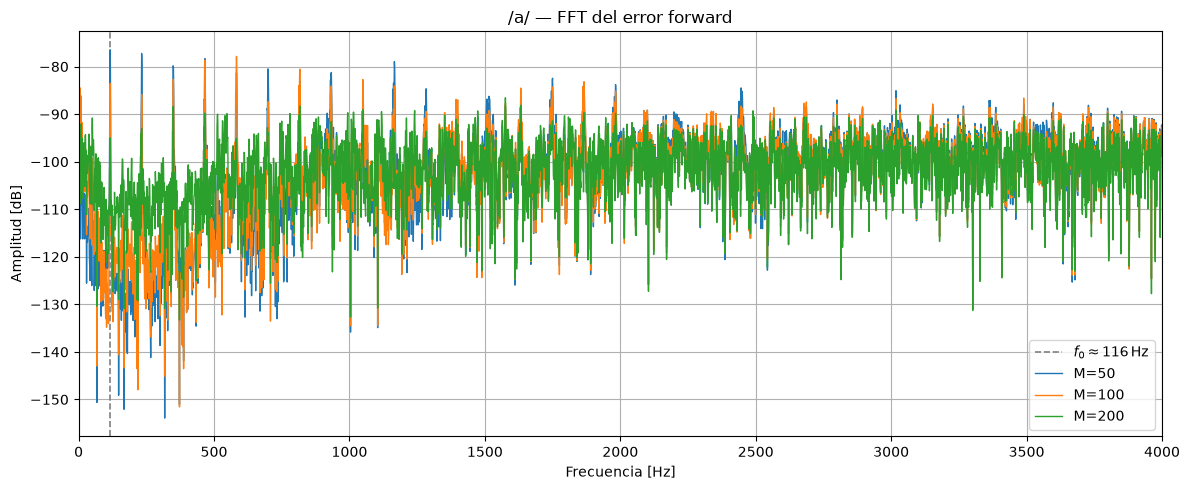

In [2]:
FMAX = 4000
F0 = 116  # Hz

fig, ax = plt.subplots(figsize=(12, 5))

x = resultados["a"]["x"]
A = resultados["a"]["A"]

# descartar primeras muestras para evitar transitorio del filtrado
n0 = max(ORDENES_ERROR)
N = len(x) - n0

ventana = np.hanning(N)
frecuencias = np.fft.rfftfreq(N, d=1/FS)

ax.axvline(F0, color="grey", linestyle="--", linewidth=1.2,
           label=fr"$f_0 \approx {F0}\,$Hz")

for M in ORDENES_ERROR:
    e = lfilter(A[M], [1.0], x)
    e = e[n0:]

    E = np.fft.rfft(e * ventana)

    magnitud = np.abs(E) / np.sum(ventana)
    if N % 2 == 0:
        magnitud[1:-1] *= 2
    else:
        magnitud[1:] *= 2

    magnitud_dB = 20 * np.log10(np.maximum(magnitud, 1e-12))
    ax.plot(frecuencias, magnitud_dB, label=f"M={M}", linewidth=1)

ax.set_title("/a/ — FFT del error forward")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel("Amplitud [dB]")
ax.set_xlim(0, FMAX)
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

Se puede observar así que la señal de error tiene presente los armónicos correspondientes a $nf_0$. También podemos ver que la energía de estos armónicos baja sustancialmente luego de $M=100$ (o sea $M>N_0$), como supusimos antes. De todas formas, aun luego del "2do codo" de $J(M)$, sigue presente energía en $nf_0$ para $M=200$, es como si el FLP no estuviese "blanqueando" $x(n)$. Esto se debe a múltiples razones:

1. La primera es que el predictor óptimo minimiza la potencia total del error, pero esto no implica que elimine completamente las componentes armónicas de la señal. Para entender esto más claramente, veamos un ejemplo.

Para ver esto, consideremos una señal formada por una componente perfectamente periódica $s(n)$, de período $N_0$, y ruido blanco $w(n)$:

$$
x(n)=s(n)+w(n), \qquad s(n)=s(n-N_0)
$$

Y supongamos un predictor que utiliza únicamente la muestra ubicada un período atrás:

$$
\hat{x}(n)=cx(n-N_0)
$$

Luego $e^f$ resulta:

$$
e^f(n)=(1-c)s(n)+w(n)-cw(n-N_0)
$$

Para eliminar completamente la componente periódica, deberíamos elegir $c=1$. Sin embargo, esto produciría $e^f(n)=w(n)-w(n-N_0)$, cuya potencia es $J(1)=2\sigma_w^2$.

En cambio, minimizando el MSE respecto de $c$:

$$
J(c)=(1-c)^2\sigma_s^2+(1+c^2)\sigma_w^2
$$

obtenemos:

$$
\boxed{c_o=\frac{\sigma_s^2}{\sigma_s^2+\sigma_w^2}}
$$

Por ejemplo, si $\sigma_s^2=9$ y $\sigma_w^2=1$, entonces $c_o=0.9$ y:

$$
e^f(n)=0.1s(n)+w(n)-0.9w(n-N_0)
$$

En este caso, $J(0.9)=1.9$, mientras que $J(1)=2$. Por tanto, conservar el 10 % de la amplitud periódica permite obtener un MSE menor que eliminarla completamente, ya que se reduce la contribución del ruido de la muestra anterior.

Y aun así, se cumple el principio de ortogonalidad:

$$
\mathbb{E}\{e^f(n)x(n-N_0)\}
=0.1(9)-0.9(1)=0
$$

O sea, el error puede ser incorrelacionado con la entrada retrasada y, al mismo tiempo, conservar componentes armónicas. Esto ocurre porque las contribuciones a la correlación se cancelan entre sí.

2. Después, la excitación glotal no es perfectamente periódica; ya que existen pequeñas variaciones en el período, la amplitud y la forma de los pulsos producidos por las cuerdas vocales. Por lo tanto, las muestras de un ciclo anterior no permiten predecir exactamente las del ciclo actual.

3. Y por último, los coeficientes del predictor se calculan mediante Levinson-Durbin utilizando una autocorrelación estimada $\hat r_x(l)$ a partir de una realización finita de la señal. Entonces, los coeficientes obtenidos no coinciden necesariamente con los óptimos teóricos. Además, se utiliza el estimador sesgado de autocorrelación, que atenúa las correlaciones estimadas para retardos grandes.

## 3.


/a/
M	J(M)/J(0) [dB]
1	-14.94
2	-18.99
4	-19.00
8	-19.71
16	-20.28
32	-20.64
64	-20.75

/sh/
M	J(M)/J(0) [dB]
1	-0.01
2	-3.05
4	-5.17
8	-6.92
16	-8.66
32	-9.40
64	-9.59


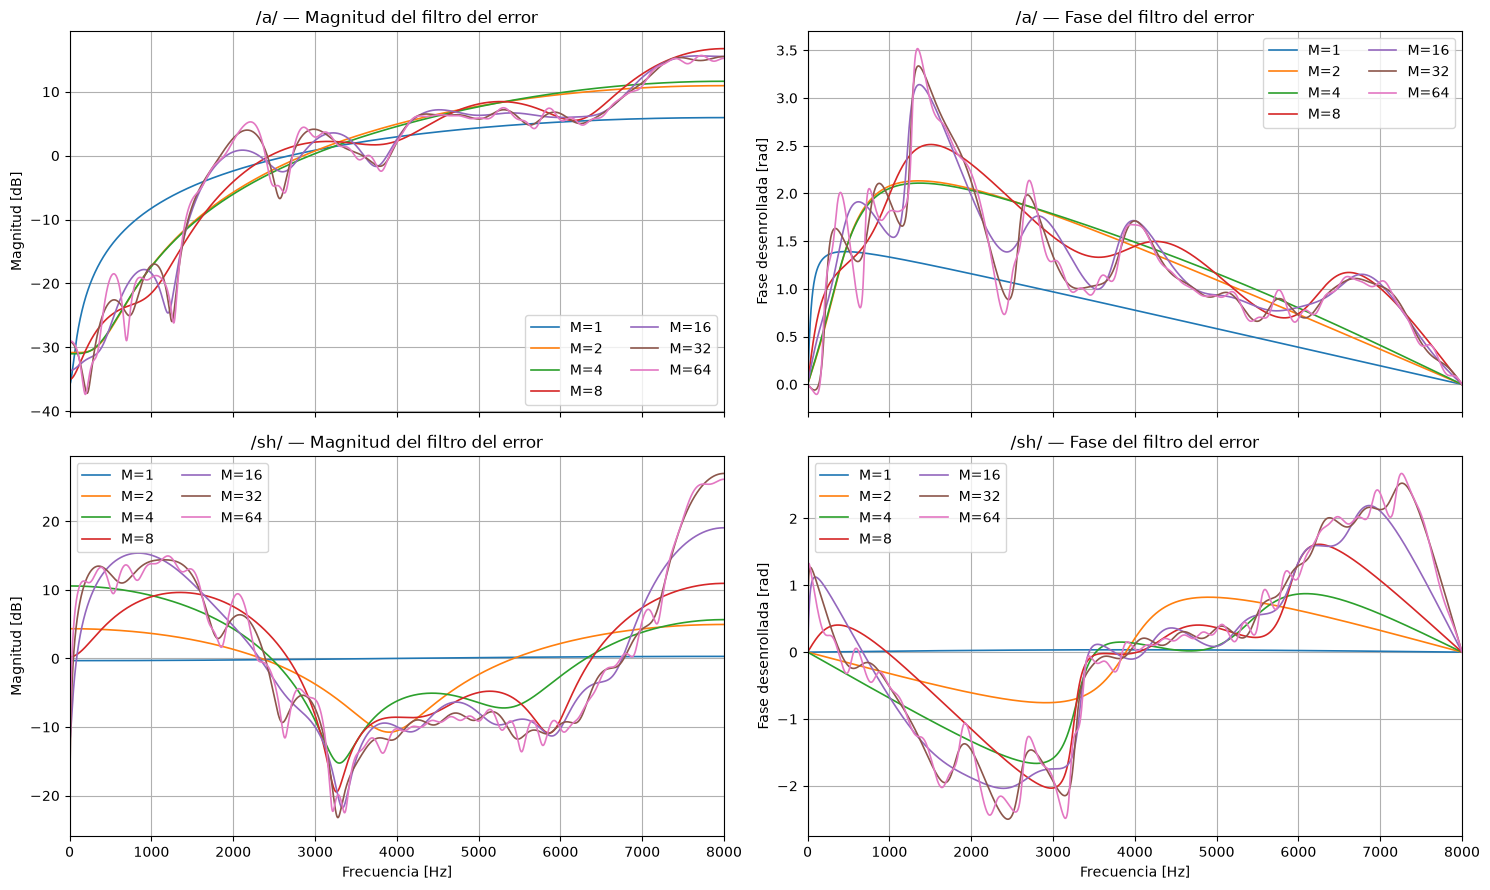

In [3]:

from scipy.signal import freqz

ORDENES_P3 = [1, 2, 4, 8, 16, 32, 64]
FMAX = 8000  # Hz (frecuencia de Nyquist)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

for fila, sonido in enumerate(("a", "sh")):
    A = resultados[sonido]["A"]
    J = resultados[sonido]["J"]

    ax_mag = axes[fila, 0]
    ax_fase = axes[fila, 1]

    print(f"\n/{sonido}/")
    print("M\tJ(M)/J(0) [dB]")

    for M in ORDENES_P3:
        # Coeficientes del filtro del error:
        # H(z) = 1 + a1*z^-1 + ... + aM*z^-M
        b = A[M]

        # Respuesta en frecuencia compleja H(e^jw)
        f, H = freqz(b, a=[1.0], worN=8192, fs=FS)

        magnitud_dB = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
        fase = np.unwrap(np.angle(H))

        ax_mag.plot(f, magnitud_dB, label=f"M={M}", linewidth=1.2)
        ax_fase.plot(f, fase, label=f"M={M}", linewidth=1.2)

        # MSE mínimo normalizado para este orden
        J_dB = 10 * np.log10(J[M] / J[0])
        print(f"{M}\t{J_dB:.2f}")

    ax_mag.set_title(f"/{sonido}/ — Magnitud del filtro del error")
    ax_mag.set_ylabel("Magnitud [dB]")
    ax_mag.set_xlim(0, FMAX)
    ax_mag.legend(ncol=2)
    ax_mag.grid(True)

    ax_fase.set_title(f"/{sonido}/ — Fase del filtro del error")
    ax_fase.set_ylabel("Fase desenrollada [rad]")
    ax_fase.set_xlim(0, FMAX)
    ax_fase.legend(ncol=2)
    ax_fase.grid(True)

axes[1, 0].set_xlabel("Frecuencia [Hz]")
axes[1, 1].set_xlabel("Frecuencia [Hz]")

plt.tight_layout()
plt.show()


Acá podemos ver cómo las respuestas en frecuencia del filtro del error aumentan la capacidad del predictor para modelar la estructura espectral de las señales a medida que crece su orden $M$.

Para /a/, se observa una fuerte atenuación de las bajas frecuencias y la aparición de mínimos locales (que pueden relacionarse con las resonancias del tracto vocal (formantes)). Para /sh/, a pesar de tratarse de una consonante sorda con excitación principalmente aleatoria, se observa una respuesta espectral selectiva, evidenciando que la señal presenta correlaciones de corto plazo.

En ambos casos, las respuestas para órdenes elevados ($M=16,32,64$) conservan una estructura general similar, lo que indica que buena parte de la información predecible de corto plazo ya ha sido modelada. Esto es consistente con el primer codo observado en $J(M)$.

Dado que los órdenes analizados son inferiores al período fundamental estimado para /a/ ($N_0=138$), con éstos gráficos podemos observar el modelado del tracto vocal, pero no caracterizar directamente el 2do codo asociado a la periodicidad glotal.

# Punto 4

/a/: potencia x = 7.824e-05, potencia x_hat = 8.345e-05
/a/ original:


/a/ sintetizada (M=32):


/sh/: potencia x = 1.366e-04, potencia x_hat = 1.256e-04
/sh/ original:


/sh/ sintetizada (M=32):


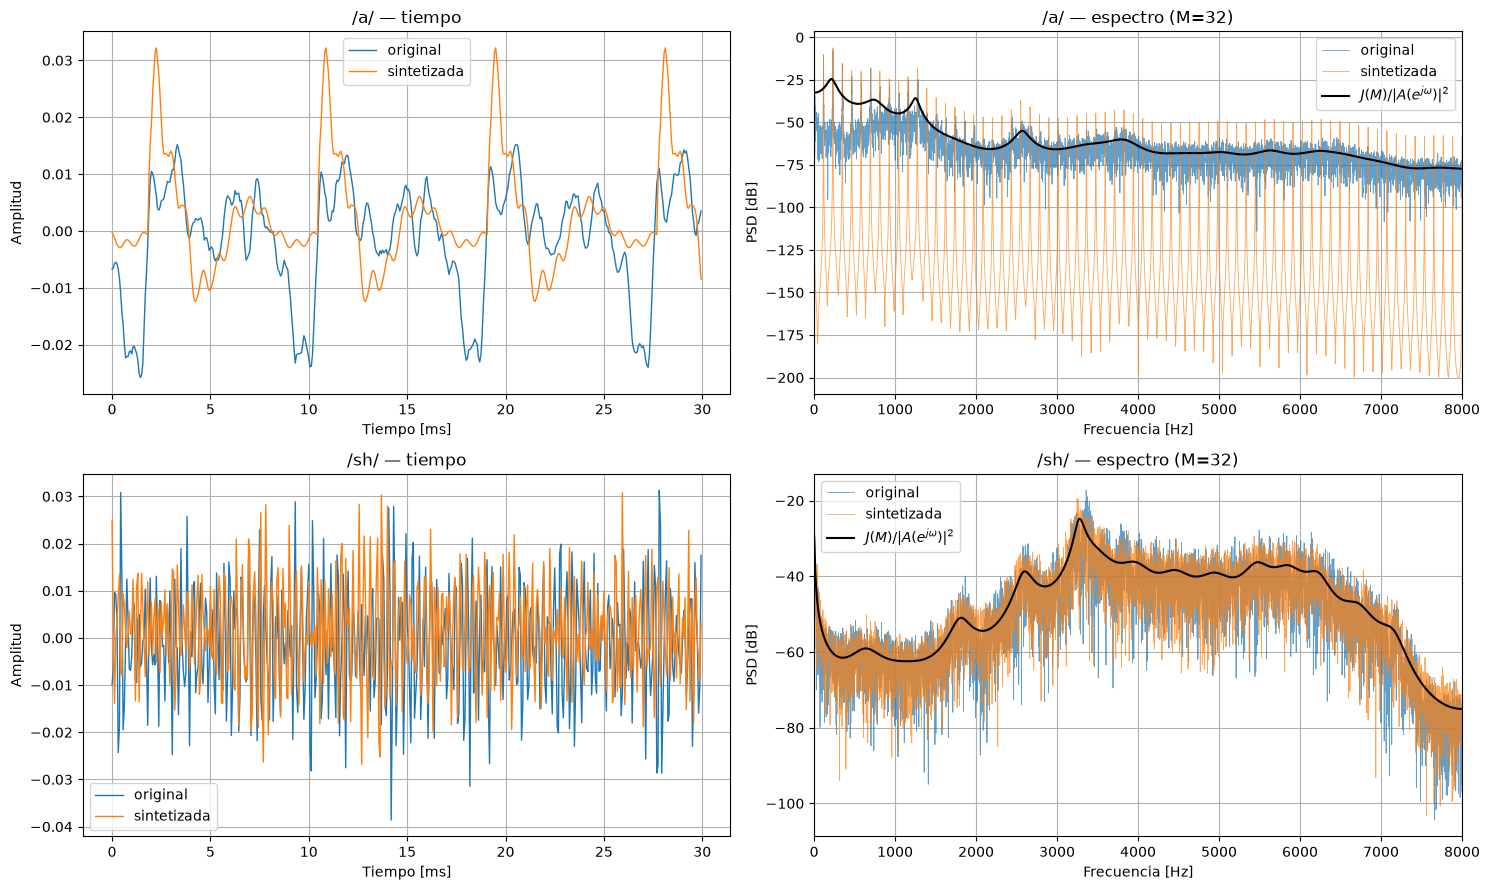

In [4]:
from scipy.signal import freqz
from IPython.display import Audio, display

M_P4 = 32   # Orden elegido: final del 1er codo de J(M)
N0 = 138    # Período de /a/ en muestras (f0 = FS/N0 ≈ 116 Hz)

rng = np.random.default_rng(0)  # Generador de ruido con semilla fija (resultados repetibles)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))  # Fila = sonido; col 0 = tiempo, col 1 = espectro

for fila, sonido in enumerate(("a", "sh")):
    x = resultados[sonido]["x"]       # Grabación original (sin continua)
    a = resultados[sonido]["A"][M_P4]  # Coeficientes [1, a1, ..., aM] del filtro del error A(z)
    J_M = resultados[sonido]["J"][M_P4]  # MSE mínimo = potencia de ef(n) para este M
    N = len(x)                         # Largo de la señal a sintetizar

    # ------------------------------------------------------------
    # 1. Modelo de la excitación ê(n), con la misma potencia que ef(n)
    # ------------------------------------------------------------
    if sonido == "a":
        G = np.sqrt(N0 * J_M)           # De G²/N0 = J(M): amplitud de cada impulso
        e_hat = np.zeros(N)             # Arranco con todo en cero
        e_hat[::N0] = G                 # Un impulso de amplitud G cada N0 muestras
    else:
        e_hat = rng.normal(0.0, np.sqrt(J_M), N)  # Ruido blanco gaussiano de varianza J(M)

    # ------------------------------------------------------------
    # 2. Síntesis: filtro inverso 1/A(z) (todo-polos, modelo AR)
    # ------------------------------------------------------------
    x_hat = lfilter([1.0], a, e_hat)    # A(z) va en el DENOMINADOR

    # Chequeo de la ganancia: las potencias deberían ser parecidas
    print(f"/{sonido}/: potencia x = {np.mean(x**2):.3e}, "   # Potencia de la original
          f"potencia x_hat = {np.mean(x_hat**2):.3e}")         # Potencia de la sintetizada

    # ------------------------------------------------------------
    # 3. Escuchar y guardar
    # ------------------------------------------------------------
    print(f"/{sonido}/ original:")                    # Etiqueta del reproductor
    display(Audio(x, rate=FS))                         # Reproductor de la grabación
    print(f"/{sonido}/ sintetizada (M={M_P4}):")       # Etiqueta del reproductor
    display(Audio(x_hat, rate=FS))                     # Reproductor de la síntesis
    sf.write(f"./audio/{sonido}_sintetizada.wav",      # Archivo de salida
             0.9 * x_hat / np.max(np.abs(x_hat)), FS)  # Normalizado para que no sature

    # ------------------------------------------------------------
    # 4. Comparación en el tiempo (unos períodos de /a/)
    # ------------------------------------------------------------
    i0, i1 = int(0.30 * FS), int(0.33 * FS)   # Tramo de 30 ms (~4 períodos de /a/)
    t = np.arange(i1 - i0) / FS * 1000        # Eje de tiempo en ms

    ax = axes[fila, 0]
    ax.plot(t, x[i0:i1], label="original", linewidth=1)        # Señal grabada
    ax.plot(t, x_hat[i0:i1], label="sintetizada", linewidth=1)  # Señal resintetizada
    ax.set_title(f"/{sonido}/ — tiempo")
    ax.set_xlabel("Tiempo [ms]")
    ax.set_ylabel("Amplitud")
    ax.legend()
    ax.grid(True)

    # ------------------------------------------------------------
    # 5. Comparación en frecuencia + envolvente del modelo AR
    # ------------------------------------------------------------
    ventana = np.hanning(N)                    # Ventana de Hann del largo de la señal
    U = np.sum(ventana**2)                     # Normalización del periodograma ventaneado
    f = np.fft.rfftfreq(N, d=1/FS)             # Eje de frecuencias en Hz

    P_x = np.abs(np.fft.rfft(x * ventana))**2 / U          # Periodograma de la original
    P_xh = np.abs(np.fft.rfft(x_hat * ventana))**2 / U     # Periodograma de la sintetizada

    _, H = freqz(a, [1.0], worN=f, fs=FS)      # A(e^jw) evaluada en las mismas frecuencias
    S_AR = J_M / np.abs(H)**2                  # PSD del modelo: J(M) / |A(e^jw)|²

    ax = axes[fila, 1]
    ax.plot(f, 10*np.log10(P_x + 1e-20), label="original", linewidth=0.6, alpha=0.7)      # Espectro de x
    ax.plot(f, 10*np.log10(P_xh + 1e-20), label="sintetizada", linewidth=0.6, alpha=0.7)  # Espectro de x_hat
    ax.plot(f, 10*np.log10(S_AR), "k", label=r"$J(M)/|A(e^{j\omega})|^2$", linewidth=1.5)  # Envolvente LPC
    ax.set_title(f"/{sonido}/ — espectro (M={M_P4})")
    ax.set_xlabel("Frecuencia [Hz]")
    ax.set_ylabel("PSD [dB]")
    ax.set_xlim(0, FS/2)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Conclusiones del punto 4

**Elección de M.** Tomamos $M=32$ para los dos sonidos porque es donde termina el primer codo de $J(M)$: de $M=32$ a $M=64$ el error casi no baja ($-20.64$ a $-20.75$ dB para /a/ y $-9.40$ a $-9.59$ dB para /sh/). Usamos el mismo orden para poder comparar los dos casos.

**Esquema.** La idea es la inversa de lo que hicimos en los puntos 2 y 3. Ahí pasábamos la voz por $A(z)$ y nos quedaba $e^f(n)$, que es lo que el predictor no pudo predecir. Acá reemplazamos $e^f(n)$ por una excitación $\hat e(n)$ inventada por nosotros y la pasamos por el filtro inverso $1/A(z)$, que es todo-polos y hace de "tracto vocal":

$$\hat e(n) \;\longrightarrow\; \frac{1}{A(z)} \;\longrightarrow\; \hat x(n)$$

**Excitación para /a/: tren de impulsos de período $N_0=138$.** En el punto 2 vimos que, con $M<N_0$, el error de /a/ todavía tiene los armónicos en $nf_0$: el predictor se comió la forma de cada pulso (los formantes) pero no la periodicidad. Entonces la excitación tiene que tener rayas en $nf_0$, y todas con la misma amplitud, porque la forma del espectro ya la pone $1/A(z)$. Un tren de deltas en frecuencia separadas $f_0$ es justamente un tren de impulsos en el tiempo de período $N_0$. Antes vimos cómo el $N_0$ estaba relacionado con a qué ordene el filtro mejora su error (el segundo codo). Pero no quiere decir que ambos números deben ser iguales. El período tiene que ser $N_0=138$ y no $M=32$: $M$ es la memoria del filtro (qué tan detallados salen los formantes), mientras que el período de la excitación fija el pitch. Con período 32 se seguiría escuchando una /a/, pero a $f_s/32=500$ Hz en vez de 116 Hz. Vale decir, no hay que adaptar la excitación para que el orden sea tal que tengamos un "segundo codo" ahí.

**Excitación para /sh/: ruido blanco gaussiano.** La /sh/ no tiene periodicidad (no tiene segundo codo), así que no hay rayas que reproducir. Y como $A(z)$ blanquea la señal, $e^f(n)$ es casi blanco. Como el "sh" es físicamente ruido coloreado, es tentador pensar que ese es impulso que hay que usar en este caso. Pero no lo coloreamos porque el color ya lo pone $1/A(z)$; si no, lo estaríamos aplicando dos veces.

**Ganancia.** Para que $\hat x(n)$ tenga la misma potencia que la grabación, le dimos a $\hat e(n)$ la misma potencia que $e^f(n)$, que es justamente $J(M)$ (Levinson nos la da directamente). Para el ruido, eso es usar varianza $J(M)$. Para el tren de impulsos, en cada período hay una sola muestra que vale $G$ y el resto vale cero, así que su potencia es $G^2/N_0$. Igualando a $J(M)$ queda $G=\sqrt{N_0\,J(M)}$. Lo comprobamos comparando la potencia de $x$ y de $\hat x$, que dan prácticamente iguales.

**La línea negra del espectro** es $J(M)/|A(e^{j\omega})|^2$, o sea la PSD de un proceso AR con esos coeficientes, excitado con ruido blanco de potencia $J(M)$. Sale de que $A(z)$ blanquea: si $|A|^2 S_x \approx J$, entonces $S_x \approx J/|A|^2$. Es la forma del espectro que $1/A(z)$ le impone a cualquier excitación. En /a/ marca los formantes (picos cerca de 800, 1250 y 2600 Hz). En /sh/ muestra que la energía está concentrada entre 2.5 y 7 kHz, o sea que la /sh/ es ruido coloreado y no blanco.

**Resultados.**

- **/sh/:**  la sintetizada suena prácticamente igual a la original. En el tiempo las señales no coinciden muestra a muestra, pero no tiene por qué: es otra realización de ruido con el mismo espectro, y eso es lo que escuchamos. En frecuencia, las dos quedan encima de la curva del modelo. El modelo anda bien porque la excitación real de la /sh/ (el aire turbulento) es efectivamente ruido.

- **/a/:**  se reconoce la /a/ y tiene el mismo tono, pero suena robótica, como un zumbido. Los formantes están bien porque la envolvente la pone $1/A(z)$, que es la misma que en la original. Las diferencias vienen de la excitación:
  1. El tren de impulsos es perfectamente periódico. La voz real tiene pequeñas variaciones de período y de amplitud entre un pulso y otro, además de algo de aire. En el espectro se ve clarito: la sintetizada tiene rayas perfectas con valles de más de 100 dB entre armónicos, mientras que en la original los armónicos están desparramados y el espacio entre ellos está relleno. Esa regularidad perfecta es lo que el oído escucha como "robótico".
  2. Un impulso no es un pulso glotal. En el tiempo se ve que la sintetizada tiene picos más angostos y no tiene la parte lenta negativa que tiene la original en cada período. Parte de la forma del pulso glotal la absorbe $A(z)$, pero no toda. Además, $1/A(z)$ es de fase mínima y el pulso real no, así que aunque el módulo del espectro coincida, la forma de onda sale distinta.

En resumen, con solo 32 coeficientes, el tipo de excitación, el período y la ganancia se puede reconstruir un sonido que se entiende. Lo que se pierde es la naturalidad, que está en las irregularidades de la excitación real. Esta es la idea de los codificadores de voz por predicción lineal, y es lo que se aplica por bloques en el punto 5.

# Punto 5

Original:


Sintetizada (M=12, tren de 160 Hz):


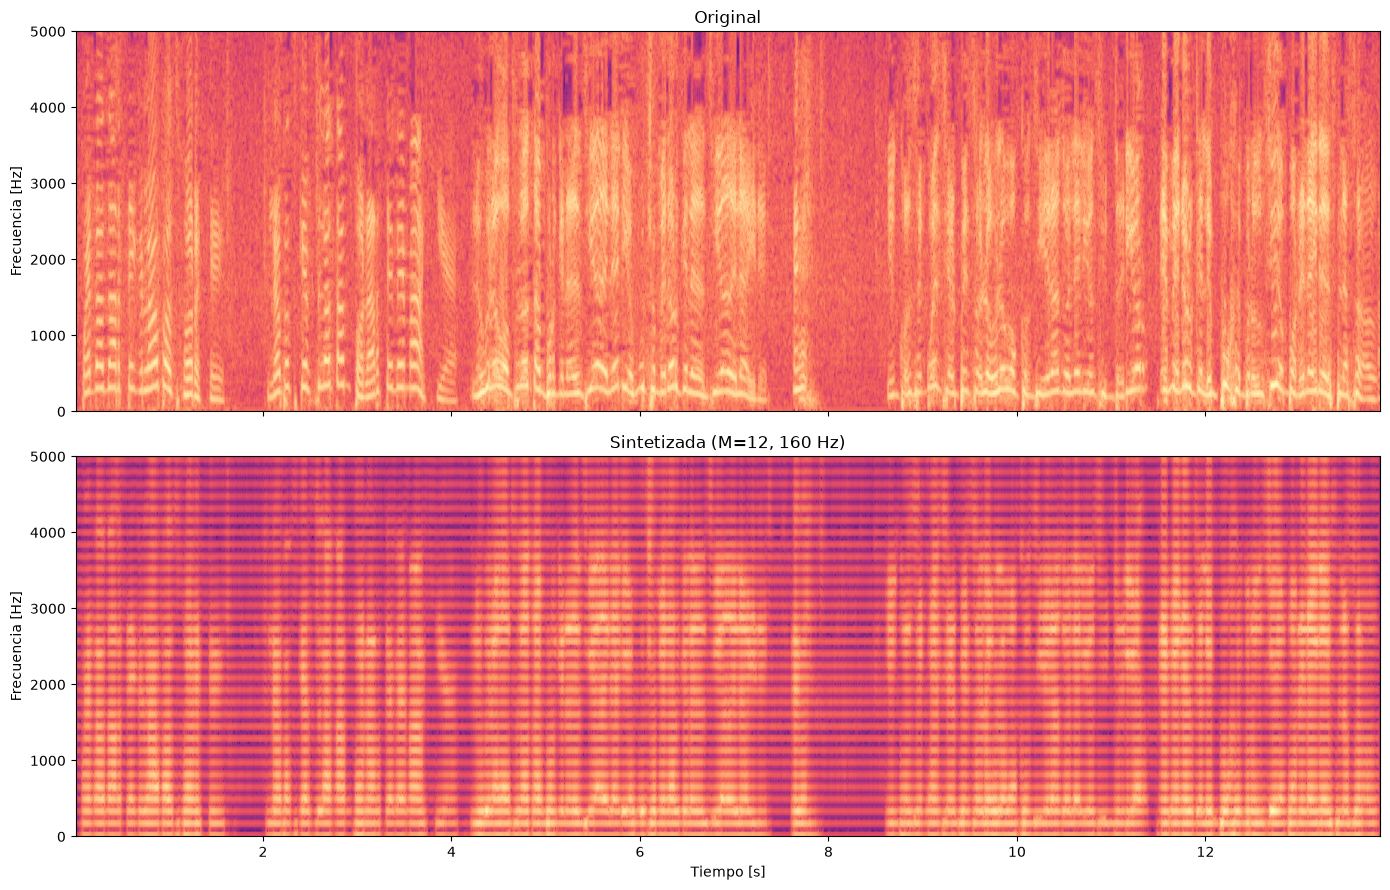

In [5]:
from scipy.signal.windows import hann
from IPython.display import Audio, display

# Parámetros de la consigna
ARCHIVO_LARGO = "./audio/audio_largo.wav"  # Grabación libre
M_P5 = 12                  # Orden del predictor por bloque
L = int(0.050 * FS)        # Largo de bloque: 50 ms = 800 muestras
HOP = L // 2               # Salto entre bloques: overlap del 50 % = 400 muestras
F_PULSOS = 160             # Frecuencia del tren de impulsos [Hz]
P = FS // F_PULSOS         # Período del tren en muestras: 16000/160 = 100

x_largo, fs = sf.read(ARCHIVO_LARGO)               # Leo la grabación
assert fs == FS, f"fs incorrecta ({fs} Hz)"         # Chequeo frecuencia de muestreo
assert x_largo.ndim == 1, "El audio debe ser mono"  # Chequeo un solo canal
x_largo = x_largo - np.mean(x_largo)                # Saco la continua, como antes
N = len(x_largo)                                    # Largo total en muestras

ventana = hann(L, sym=False)   # Hann "periódica": con 50 % de overlap suma exactamente constante

# Tren de impulsos GLOBAL: así los impulsos caen en n = 0, 100, 200, ... del tiempo total,
# y cada bloque toma su pedazo sin reiniciar la fase (coherente entre bloques)
tren = np.zeros(N)   # Arranco con todo en cero
tren[::P] = 1.0      # Un impulso unitario cada P muestras

y = np.zeros(N)                       # Acá se acumula la señal sintetizada (overlap-add)
n_bloques = 1 + (N - L) // HOP        # Cantidad de bloques completos que entran

for b in range(n_bloques):
    ini = b * HOP                     # Muestra donde empieza el bloque
    fin = ini + L                     # Muestra donde termina el bloque

    # ------------------------------------------------------------
    # 1. Análisis: predicción forward del bloque ventaneado
    # ------------------------------------------------------------
    x_bloque = x_largo[ini:fin] * ventana        # Bloque con ventana de Hann
    r = autocorrelacion(x_bloque, M_P5)          # r(0), ..., r(M) del bloque
    if r[0] < 1e-12:                             # Bloque sin energía (silencio digital)
        continue                                 # Lo salteo: Levinson dividiría por cero
    J, A = levinson_durbin(r, M_P5)              # MSE mínimo y filtros del error del bloque
    a = A[M_P5]                                  # Coeficientes [1, a1, ..., a12] de A(z)

    # ------------------------------------------------------------
    # 2. Reemplazo el error por el tren de impulsos (misma potencia que ef)
    # ------------------------------------------------------------
    G = np.sqrt(P * J[M_P5])                     # Igual que en el punto 4: G²/P = J(M)
    e_bloque = G * tren[ini:fin]                 # Pedazo del tren global que cae en este bloque

    # ------------------------------------------------------------
    # 3. Síntesis: filtro inverso 1/A(z) del bloque
    # ------------------------------------------------------------
    y_bloque = lfilter([1.0], a, e_bloque)       # A(z) en el denominador

    # ------------------------------------------------------------
    # 4. Ventaneo y sumo en su lugar (overlap-add)
    # ------------------------------------------------------------
    y[ini:fin] += y_bloque * ventana             # Ventana de Hann y suma en su tiempo

# ------------------------------------------------------------
# Escuchar y guardar
# ------------------------------------------------------------
print("Original:")                                  # Etiqueta del reproductor
display(Audio(x_largo, rate=FS))                     # Reproductor de la grabación
print(f"Sintetizada (M={M_P5}, tren de {F_PULSOS} Hz):")  # Etiqueta del reproductor
display(Audio(y, rate=FS))                           # Reproductor de la síntesis
sf.write("./audio/audio_largo_sintetizado.wav",      # Archivo de salida
         0.9 * y / np.max(np.abs(y)), FS)            # Normalizado para que no sature

# ------------------------------------------------------------
# Comparación: espectrogramas
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)  # Uno arriba del otro

for ax, senal, titulo in zip(axes, (x_largo, y), ("Original", f"Sintetizada (M={M_P5}, {F_PULSOS} Hz)")):
    ax.specgram(senal, NFFT=512, Fs=FS, noverlap=384, cmap="magma")  # Espectrograma (STFT)
    ax.set_title(titulo)
    ax.set_ylabel("Frecuencia [Hz]")
    ax.set_ylim(0, 5000)          # Zona donde están los formantes

axes[1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

### Conclusiones del punto 5

Antes de concluir, repasemos qué hicimos en este inciso.Es el mismo esquema del punto 4, pero aplicado por bloques. Para cada bloque calculamos la predicción forward con Levinson (como en el punto 2) y nos quedamos con su $A(z)$ y su $J(M)$. Después tiramos el error $e^f(n)$, lo reemplazamos por un tren de impulsos y lo filtramos con $1/A(z)$ (como en el punto 4). Del audio solo usamos $A(z)$ y $J$ de cada bloque, o sea cómo está el tracto vocal y con cuánta fuerza se habla en cada momento. La excitación es inventada y es la misma para todo el audio. No hace falta que la grabación sea de la misma persona ni con el mismo micrófono que las de /a/ y /sh/: cada $A(z)$ sale del propio audio largo. Usamos una conversación entre dos personas, y como cada bloque se analiza por separado, los $A(z)$ siguen a quien esté hablando en ese momento.

**Por qué por bloques.** En los puntos anteriores teníamos 1 s de un sonido sostenido, donde el tracto vocal está quieto y la señal es más o menos estacionaria, así que un solo $A(z)$ alcanzaba. En una frase, la boca cambia de forma con cada fonema, y la predicción lineal supone que la autocorrelación no cambia en el tiempo. Si calculáramos un solo $A(z)$ para los 14 s, nos daría un promedio de todos los fonemas, y la salida sería mucho peor. Con bloques de 50 ms la boca casi no se mueve adentro de cada bloque (la señal es estacionaria de a pedacitos), y aun así hay 800 muestras para estimar bien $r(0),\dots,r(12)$. La ventana de Hann con 50 % de overlap hace que los bloques se empalmen suave, sin saltos entre uno y otro.

**Por qué $M=12$.** Cada formante es un par de polos complejos de $1/A(z)$, así que con 12 coeficientes se pueden modelar unas 5 o 6 resonancias, que es lo que necesita la voz hasta 8 kHz. Además, $M=12$ es mucho menor que el período del pitch (100 muestras o más), así que el predictor no llega a ver la periodicidad. Es lo mismo que pasaba con el primer codo de $J(M)$: el filtro se queda solo con los formantes y la periodicidad queda en la excitación, que es justamente lo que reemplazamos.

**Tren de impulsos coherente.** Armamos un único tren de impulsos para todo el audio, con un impulso cada $P = f_s/160 = 100$ muestras, y cada bloque toma el pedazo que le corresponde. Si cada bloque arrancara su propio tren desde cero, los impulsos de bloques vecinos quedarían desfasados entre sí, y al sumarlos aparecerían clicks e impulsos duplicados.

**Ganancia por bloque.** La consigna no lo pide, pero si todos los bloques tuvieran la misma excitación, las pausas sonarían igual de fuerte que las vocales. Es decir, no habría silencio. Por eso a cada bloque le dimos la misma potencia que su error de predicción, igual que en el punto 4: $G^2/P = J(M)$, o sea $G=\sqrt{P\,J(M)}$. Los bloques de silencio total se saltean, porque ahí $r(0)=0$ y Levinson dividiría por cero.

**Ventana.** Usamos la ventana de Hann "periódica" (`sym=False`), porque con 50 % de overlap dos ventanas corridas suman exactamente 1. Así el overlap-add no mete cambios de volumen cada 25 ms.

**Resultados.** La señal sintetizada se entiende, pero es una versión robotizada de la original. En los espectrogramas se ve por qué:

- **Lo que se mantiene:** las zonas de energía (los formantes) de la sintetizada siguen a las de la original en el tiempo, porque $A(z)$ se recalcula en cada bloque. Por eso se entiende qué se dice. También se mantienen las pausas y los cambios de volumen, gracias a la ganancia de cada bloque.
- **La entonación:** en la original los armónicos son curvos y su separación cambia, porque el pitch sube y baja con la entonación de cada persona. En la sintetizada son rayas horizontales perfectas cada 160 Hz durante todo el audio. Por eso suena monótona.
- **Los sonidos sordos (s, sh, f, j):** en la original son zonas de ruido sin armónicos (las franjas verticales, por ejemplo cerca de 2 s y de 8 s). En la sintetizada aparecen con las mismas rayas de 160 Hz, porque los excitamos con impulsos cuando en realidad su excitación es ruido. Por eso suenan zumbando en vez de soplando.
- **Las dos voces se parecen más entre sí**, porque gran parte de lo que distingue a una persona es su pitch y su entonación, y eso lo reemplazamos por lo mismo para las dos. Lo que queda de diferencia viene de los formantes, que dependen de la forma del tracto vocal de cada una.

En resumen, este punto muestra cómo se reparte la información de la voz: **$A(z)$ lleva qué se dice**, y **la excitación lleva cómo se dice** (tono, entonación, si es sonoro o sordo, y buena parte de quién habla). Esta es la idea de los vocoders por predicción lineal, que en vez de mandar las 400 muestras nuevas de cada bloque mandan 12 coeficientes y una ganancia. Para que sonara más natural habría que hacer lo mismo que en los puntos 2 y 4, pero por bloque: estimar el período del pitch de cada bloque (por ejemplo, con el pico de la autocorrelación) y decidir si el bloque es sonoro o sordo, para excitarlo con impulsos o con ruido según corresponda.